# La ecuación 11 y el flujo de entropía por el borde

Este notebook explica, con fórmulas, la diferencia entre las corridas **"paper (eq. 11 as written)"**
y **"paper, corrected"** de `wpinn_best.ipynb`. La idea en una línea:

> La ecuación 11 del paper pide que la entropía total dentro del dominio no aumente. Pero la
> desigualdad de entropía, integrada sobre un dominio acotado, dice otra cosa: que la entropía
> **más lo que sale por el borde** no aumente. Si entra entropía por el borde, la ecuación 11
> castiga a la solución correcta.

Al final se verifica todo numéricamente con la solución exacta del choque móvil, sin entrenar
ninguna red.

## 1. Entropía de Kruzhkov

La ley de conservación es

$$u_t + \partial_x H(u) + \partial_y H(u) = 0, \qquad H(u) = \frac{u^2}{2}.$$

Para cada constante $c$ se define el par **entropía / flujo de entropía** de Kruzhkov:

$$\eta(u) = |u - c|, \qquad Q(u, c) = \operatorname{sign}(u - c)\,\big(H(u) - H(c)\big).$$

La solución físicamente correcta (la de entropía) cumple, para toda $c$, la **desigualdad de
entropía**

$$\partial_t |u - c| + \partial_x Q(u, c) + \partial_y Q(u, c) \;\le\; 0. \tag{9}$$

Es la ecuación 9 del paper. Se lee como un balance: la entropía en un punto sólo puede cambiar
porque fluye ($\partial_x Q + \partial_y Q$) o porque se **destruye** (el "$< 0$"), y nunca se crea.
En los choques se destruye; donde la solución es suave se conserva.

Escribiéndolo con el campo vectorial $\mathbf{F} = (Q, Q)$:

$$\partial_t |u - c| + \nabla \cdot \mathbf{F} \;\le\; 0 .$$

## 2. De la desigualdad local a una global: el teorema de la divergencia

La ecuación 9 es **local** (vale punto a punto). Para obtener algo sobre la entropía **total** del
dominio $\Omega = [-1, 1]^2$ se integra sobre $\Omega$:

$$\int_\Omega \partial_t |u - c| \,dx\,dy \;+\; \int_\Omega \nabla \cdot \mathbf{F} \,dx\,dy \;\le\; 0 .$$

- El primer término es la derivada de la entropía total:
  $\displaystyle \int_\Omega \partial_t |u - c| = \frac{d}{dt} E(t)$, con $\displaystyle E(t) = \int_\Omega |u - c|\,dx\,dy$.
- El segundo, por el **teorema de la divergencia**, es el flujo a través del borde:
  $\displaystyle \int_\Omega \nabla \cdot \mathbf{F} = \oint_{\partial\Omega} \mathbf{F} \cdot n \, ds$,
  con $n$ la normal exterior.

Resultado:

$$\boxed{\;\frac{d}{dt} E(t) \;+\; \underbrace{\oint_{\partial\Omega} \mathbf{F}\cdot n \, ds}_{B(t):\ \text{flujo neto que sale}} \;\le\; 0\;}$$

Es el mismo balance de antes, pero para todo el dominio: **la entropía de adentro más la que
sale por el borde no puede aumentar.** Si entra entropía por el borde ($B < 0$), la de adentro
**sí puede** aumentar, hasta $-B$.

## 3. Qué escribe el paper

La ecuación 11 del paper es

$$\mathcal{L}_1 = \mathcal{L}_0 + \frac{d}{dt}\int_\Omega \eta(u)\,dx\,dy ,$$

es decir, pide

$$\frac{d}{dt} E(t) \;\le\; 0 \qquad \text{(sin el término } B\text{)}.$$

Esto coincide con la desigualdad correcta **sólo si $B = 0$**: dominio periódico, o una solución
que no hace fluir entropía por el borde. En el choque móvil eso **no** pasa, porque por el borde
izquierdo entra continuamente $u = 1$.

| | Condición que se impone |
|---|---|
| ecuación 11 (paper, "as written") | $\dfrac{dE}{dt} \le 0$ |
| corregida ("corrected") | $\dfrac{dE}{dt} + B \le 0$ |

## 4. Cuentas exactas para el choque móvil

La solución exacta es $u = 1$ si $x < x_s(t)$ y $u = 0$ si $x > x_s(t)$, con el choque en
$x_s(t) = t/2$ (velocidad $s = 1/2$). No depende de $y$.

### 4.1 La entropía total y su derivada

El cuadrado tiene alto 2. A la izquierda del choque hay un rectángulo de ancho $x_s + 1$ donde
$|u - c| = |1 - c|$, y a la derecha uno de ancho $1 - x_s$ donde $|u - c| = |c|$:

$$E(t) = 2\Big[(x_s + 1)\,|1 - c| + (1 - x_s)\,|c|\Big].$$

Derivando, con $x_s' = 1/2$:

$$\frac{dE}{dt} = 2 \cdot \tfrac{1}{2}\,\big(|1 - c| - |c|\big) = |1 - c| - |c| .$$

**Al avanzar, el choque cambia una franja de $u = 0$ por $u = 1$.** Si $c < 1/2$, el valor $u = 1$
está más lejos de $c$ que $u = 0$, así que $|u - c|$ crece: **la entropía total aumenta**, y la
ecuación 11 lo castiga.

### 4.2 El flujo por el borde

Las cuatro caras del cuadrado, con su normal exterior:

| cara | normal $n$ | $\mathbf{F}\cdot n$ | valor de $u$ |
|---|---|---|---|
| $x = 1$ | $(1, 0)$ | $+Q$ | $0$ |
| $x = -1$ | $(-1, 0)$ | $-Q$ | $1$ |
| $y = 1$ | $(0, 1)$ | $+Q$ | igual que en $y = -1$ |
| $y = -1$ | $(0, -1)$ | $-Q$ | igual que en $y = 1$ |

Las caras $y = \pm 1$ se cancelan (la solución no depende de $y$; en el código, condición
periódica). Quedan las caras $x = \pm 1$, cada una de largo 2:

$$B = 2\,\big[\,Q(0, c) - Q(1, c)\,\big].$$

Con $H(u) = u^2/2$:

$$Q(1, c) = \operatorname{sign}(1 - c)\Big(\tfrac12 - \tfrac{c^2}{2}\Big), \qquad
Q(0, c) = \operatorname{sign}(-c)\Big(0 - \tfrac{c^2}{2}\Big) = \operatorname{sign}(c)\,\tfrac{c^2}{2}.$$

### 4.3 Juntando todo

| rango de $c$ | $\dfrac{dE}{dt}$ (ec. 11) | $B$ | $\dfrac{dE}{dt} + B$ (corregida) |
|---|---|---|---|
| $c < 0$ | $1$ | $-1$ | $0$ |
| $0 < c < 1$ | $1 - 2c$ | $2c^2 - 1$ | $-2c(1 - c)$ |
| $c > 1$ | $-1$ | $1$ | $0$ |

- **La corregida** da $\le 0$ para todo $c$: la solución exacta la cumple. El $0$ fuera de $[0,1]$
  es la conservación de masa (lo que entra por la izquierda es lo que acumula el dominio). El
  $-2c(1-c) < 0$ dentro de $[0,1]$ es la entropía que **destruye el choque**: lo que lo hace
  físicamente admisible.
- **La ecuación 11** da $\dfrac{dE}{dt} = 1 - 2c > 0$ para $c < 1/2$ (y $= 1$ para $c < 0$): **la
  solución exacta la viola.** Una pérdida construida con ella castiga justo a la respuesta
  correcta.

## 5. Por qué la red prefería un choque quieto

Considérese la "solución" falsa en que el choque **no se mueve** ($u = u_0$ para todo $t$):

- $E(t)$ es constante, así que $\dfrac{dE}{dt} = 0$: **la ecuación 11 queda satisfecha para todo
  $c$.** Para esa pérdida, el choque quieto es perfecto.
- El flujo por el borde es el mismo de antes, $B = 2c^2 - 1$ en $0 < c < 1$ y $B = 1$ en $c > 1$.
  Entonces la corregida da $\dfrac{dE}{dt} + B = B > 0$ para $c > 1/\sqrt{2}$: **la versión
  corregida sí castiga al choque quieto.** Para $c > 1$ dice exactamente "entra masa por la
  izquierda y el dominio no la acumula", que es la conservación de masa violada.

| | choque correcto ($x_s = t/2$) | choque quieto ($x_s = 0$) |
|---|---|---|
| ecuación 11 | **castigado** ($c < 1/2$) | aceptado |
| corregida | aceptado | **castigado** ($c > 1/\sqrt{2}$) |

Ésa es la razón por la que "paper (eq. 11 as written)" dejaba el choque cerca de $x = 0$.

## 6. Verificación numérica

Se calculan $\dfrac{dE}{dt}$ y $B$ **numéricamente** (integrando sobre una malla, no con las
fórmulas de arriba) para el choque correcto y para el choque quieto, y se comparan con las
fórmulas de la tabla.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use("notebook.mplstyle")

T = 0.5
shock_speed = 0.5
x_grid = np.linspace(-1.0, 1.0, 20001)   # malla fina en x: la solución no depende de y
y_length = 2.0                           # alto del cuadrado [-1, 1]
c_values = np.linspace(-0.25, 1.25, 301)


def flux(u):
    return 0.5 * u**2


def entropy_flux(u, c):
    # Q(u, c) = sign(u - c) (H(u) - H(c))
    return np.sign(u - c) * (flux(u) - flux(c))


def shock_profile(time, speed):
    # u = 1 a la izquierda del choque y 0 a la derecha; speed = 0.5 es el correcto, 0 el quieto.
    return np.where(x_grid <= speed * time, 1.0, 0.0)


def entropy_balance(speed):
    # Devuelve (dE/dt, B) para cada c, calculados sobre la malla.
    rate = []
    boundary = []
    for c in c_values:
        # Entropía total: integral de |u - c| en x (regla del trapecio) por el alto en y.
        total_entropy_start = y_length * np.trapezoid(np.abs(shock_profile(0.0, speed) - c), x_grid)
        total_entropy_end = y_length * np.trapezoid(np.abs(shock_profile(T, speed) - c), x_grid)
        # La entropía cambia a ritmo constante (el choque avanza a velocidad constante).
        rate.append((total_entropy_end - total_entropy_start) / T)
        # Flujo que sale por x = 1 (u = 0) menos el que entra por x = -1 (u = 1), por el largo 2.
        boundary.append(y_length * (entropy_flux(0.0, c) - entropy_flux(1.0, c)))
    return np.array(rate), np.array(boundary)


moving_rate, moving_boundary = entropy_balance(speed=shock_speed)
still_rate, still_boundary = entropy_balance(speed=0.0)

# Comparación con las fórmulas de la tabla 4.3 (choque correcto).
formula_rate = np.abs(1 - c_values) - np.abs(c_values)
formula_boundary = 2 * (np.sign(c_values) * c_values**2 / 2 - np.sign(1 - c_values) * (0.5 - c_values**2 / 2))
print("max |numeric - formula|, dE/dt:", np.abs(moving_rate - formula_rate).max())
print("max |numeric - formula|, B    :", np.abs(moving_boundary - formula_boundary).max())

max |numeric - formula|, dE/dt: 1.1102230246251565e-15
max |numeric - formula|, B    : 0.0


#### Figura 1: qué castiga cada versión

**Figura 1.** Para cada constante $c$, la cantidad que cada versión exige que sea $\le 0$. La zona
sombreada ($> 0$) es lo que la pérdida **castiga**. Izquierda: el choque correcto. La ecuación 11
(gris discontinuo) entra en la zona castigada para $c < 1/2$; la corregida (azul) nunca. Derecha:
el choque quieto. La ecuación 11 vale 0 para todo $c$ (aceptado); la corregida entra en la zona
castigada para $c > 1/\sqrt{2} \approx 0.71$. Las líneas punteadas verticales marcan $c = 0$ y
$c = 1$, el rango de $u$.

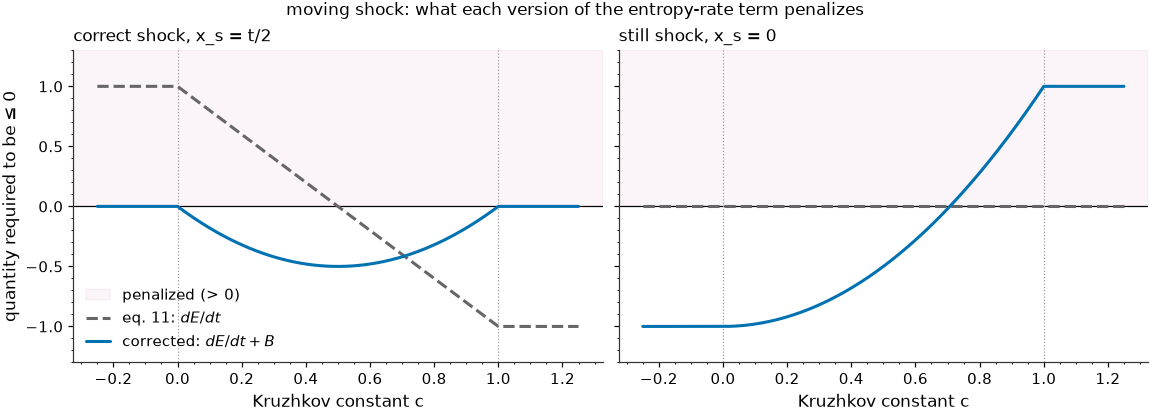

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True, layout="constrained")
cases = [("correct shock, x_s = t/2", moving_rate, moving_boundary),
         ("still shock, x_s = 0", still_rate, still_boundary)]
for ax, (title, rate, boundary) in zip(axes, cases):
    ax.axhspan(0.0, 1.3, color="C3", alpha=0.08, label="penalized (> 0)")
    ax.axhline(0.0, color="black", linewidth=0.8)
    for c_limit in (0.0, 1.0):
        ax.axvline(c_limit, color="0.6", linestyle=":", linewidth=0.8)
    ax.plot(c_values, rate, color="0.4", linestyle="--", linewidth=2.0, label=r"eq. 11: $dE/dt$")
    ax.plot(c_values, rate + boundary, color="C0", linestyle="-", linewidth=2.0, label=r"corrected: $dE/dt + B$")
    ax.set_title(title)
    ax.set_xlabel("Kruzhkov constant c")
    ax.set_ylim(-1.3, 1.3)
axes[0].set_ylabel("quantity required to be ≤ 0")
axes[0].legend(loc="lower left")
fig.suptitle("moving shock: what each version of the entropy-rate term penalizes")
plt.show()

## 7. Cómo entra en la pérdida

En la wPINN la desigualdad se integra también en el tiempo, $t \in [0, T]$:

$$\int_0^T \Big(\frac{dE}{dt} + B\Big) dt \;=\; \underbrace{\int_0^T\!\!\int_\Omega \partial_t |u - c|}_{\text{tasa de entropía}} \;+\; \underbrace{\int_0^T\!\!\oint_{\partial\Omega} \mathbf{F}\cdot n}_{\text{flujo por el borde}} \;\le\; 0 .$$

En el código (`wpinn_simple.ipynb`, sección 1.6) cada término se estima por Monte Carlo:

| término | estimación | código |
|---|---|---|
| tasa de entropía | $\lvert D \rvert \cdot \operatorname{media}\big(\operatorname{sign}(u - c)\, u_t\big)$ sobre los puntos interiores | `integrand + sign * u_t` en `weak_residual` |
| flujo por el borde | $2T \cdot \big[\operatorname{media}_{x = 1} Q - \operatorname{media}_{x = -1} Q\big]$ | `boundary_entropy_flux` |

- **"paper (eq. 11 as written)"** usa sólo la tasa: `train_wpinn(..., entropy_boundary_flux=False)`.
- **"paper, corrected"** usa las dos: es el valor por defecto.

Las dos se suman al residual de Kruzhkov (L0) y pasan por la misma normalización y el mismo
$\operatorname{ReLU}$; ésa es la única diferencia entre las dos corridas.